<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_EXP13_PRELAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 26.4M/26.4M [00:38<00:00, 681kB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 132kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.1MB/s]


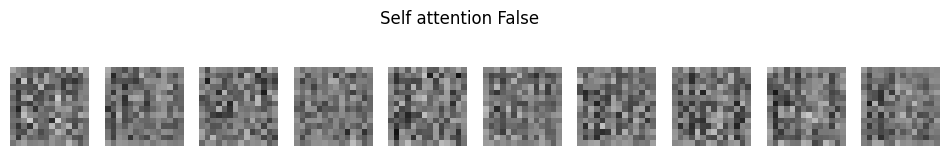

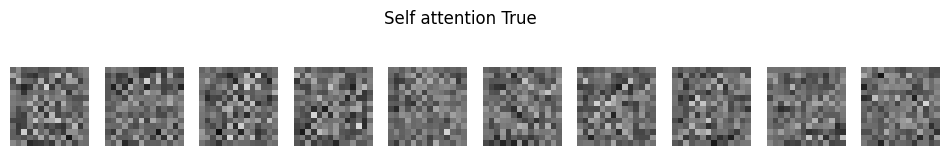

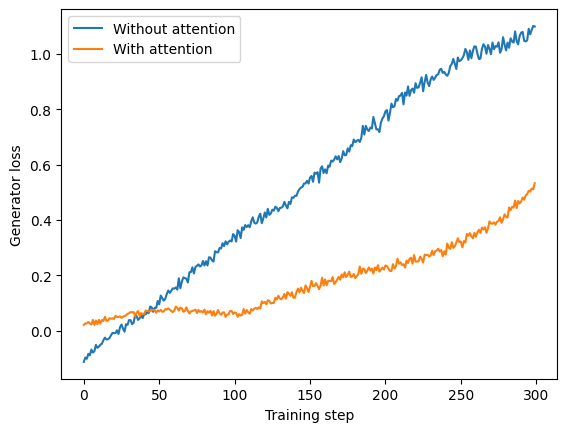

In [ ]:

import torch
from torch import nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_num_threads(2)

device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.Compose([
    transforms.Resize((14, 14)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

data = datasets.FashionMNIST(
    "/content/data", download=True, transform=transform
)

loader = torch.utils.data.DataLoader(
    data, batch_size=64, shuffle=True, drop_last=True
)

# Self Attention Layer
class SelfAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.attn = nn.MultiheadAttention(
            8, num_heads=1, batch_first=True
        )

        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):

        b, c, h, w = x.shape

        tokens = x.flatten(2).transpose(1, 2)

        out, _ = self.attn(
            tokens, tokens, tokens,
            need_weights=False
        )

        out = out.transpose(1, 2).reshape(b, c, h, w)

        return x + self.gamma * out


# GAN Training
def run(attention=True, steps=300):

    torch.manual_seed(7)

    # Generator
    G = nn.Sequential(
        nn.Linear(32, 8*7*7),
        nn.ReLU(),
        nn.Unflatten(1, (8, 7, 7)),
        SelfAttention() if attention else nn.Identity(),
        nn.ConvTranspose2d(8, 1, 4, 2, 1),
        nn.Tanh()
    ).to(device)

    # Discriminator
    D = nn.Sequential(
        nn.Conv2d(1, 8, 4, 2, 1),
        nn.LeakyReLU(0.2),
        SelfAttention() if attention else nn.Identity(),
        nn.Flatten(),
        nn.Linear(8*7*7, 1)
    ).to(device)

    og = torch.optim.Adam(
        G.parameters(), lr=0.0002, betas=(0.0, 0.9)
    )

    od = torch.optim.Adam(
        D.parameters(), lr=0.0002, betas=(0.0, 0.9)
    )

    batches = iter(loader)
    history = []

    for step in range(steps):

        try:
            real, _ = next(batches)

        except StopIteration:
            batches = iter(loader)
            real, _ = next(batches)

        real = real.to(device)

        n = len(real)

        fake = G(
            torch.randn(n, 32, device=device)
        )

        # Discriminator update
        real_score = D(real)
        fake_score = D(fake.detach())

        ld = (
            torch.relu(1-real_score).mean()
            + torch.relu(1+fake_score).mean()
        )

        od.zero_grad()
        ld.backward()
        od.step()

        # Generator update
        for p in D.parameters():
            p.requires_grad_(False)

        lg = -D(fake).mean()

        og.zero_grad()
        lg.backward()
        og.step()

        for p in D.parameters():
            p.requires_grad_(True)

        history.append(lg.item())

    # Generate images
    with torch.no_grad():

        images = G(
            torch.randn(10, 32, device=device)
        )

        images = images.cpu().squeeze(1)

    fig, axes = plt.subplots(1, 10, figsize=(12, 2))

    for ax, img in zip(axes, images):
        ax.imshow(
            (img+1)/2, cmap="gray",
            vmin=0, vmax=1
        )
        ax.axis("off")

    plt.suptitle("Self attention " + str(attention))
    plt.show()

    return history


# Compare without and with attention
without = run(attention=False)

with_attention = run(attention=True)

# Plot comparison
plt.plot(without, label="Without attention")
plt.plot(with_attention, label="With attention")

plt.xlabel("Training step")
plt.ylabel("Generator loss")

plt.legend()
plt.show()
